In [1]:
from pathlib import Path
import pickle
import numpy as np
import dlib
from matplotlib import pyplot as plt
import pandas as pd
import seaborn as sns
import skfuzzy as fuzz
import sys

from pyfume import (
    Clusterer,
    AntecedentEstimator,
    FireStrengthCalculator,
    ConsequentEstimator,
    SugenoFISBuilder,
    SugenoFISTester,
)

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)


from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from src.preprocess import preprocess_kdef_image
from sklearn.cluster import KMeans
from sklearn.metrics import mean_squared_error

In [2]:
import numpy as np
from pathlib import Path

BASE = Path(".")

with np.load(
    BASE / "data/kdef_preprocessed.npz",
    allow_pickle=False
) as data:
    X_train = data["X_train"].astype(np.float32)
    y_train = data["y_train"]
    X_test = data["X_test"].astype(np.float32)
    y_test = data["y_test"]

print("Training:", X_train.shape)
print("Test:", X_test.shape)

Training: (784, 48, 48)
Test: (196, 48, 48)


In [3]:
def normalize_images(images):
    images = np.asarray(images, dtype=np.float32)

    if not np.isfinite(images).all():
        raise ValueError("Images contain NaN or infinite values.")

    minimum = images.min()
    maximum = images.max()

    if minimum < 0 or maximum > 255:
        raise ValueError(f"Unexpected pixel range: {minimum} to {maximum}")

    if maximum > 1:
        images = images / 255.0

    return images


X_train = normalize_images(X_train)
X_test = normalize_images(X_test)

print("Training:", X_train.shape, X_train.min(), X_train.max())
print("Test:", X_test.shape, X_test.min(), X_test.max())

Training: (784, 48, 48) 0.015686275 0.98039216
Test: (196, 48, 48) 0.015686275 0.9529412


In [4]:
predictor_path = (
    BASE / "faceAndLandmarkModels/shape_predictor_68_face_landmarks.dat"
)

landmark_predictor = dlib.shape_predictor(str(predictor_path))


def extract_landmarks(img):
    img_uint8 = np.ascontiguousarray(
        np.round(img * 255).astype(np.uint8)
    )

    height, width = img_uint8.shape

    # The saved image is already a cropped face
    face_rect = dlib.rectangle(0, 0, width - 1, height - 1)

    shape = landmark_predictor(img_uint8, face_rect)

    return np.array(
        [(point.x, point.y) for point in shape.parts()],
        dtype=np.float32
    )


landmarks_train = np.stack([
    extract_landmarks(img) for img in X_train
])

landmarks_test = np.stack([
    extract_landmarks(img) for img in X_test
])

print("Training landmarks:", landmarks_train.shape)
print("Test landmarks:", landmarks_test.shape)

Training landmarks: (784, 68, 2)
Test landmarks: (196, 68, 2)


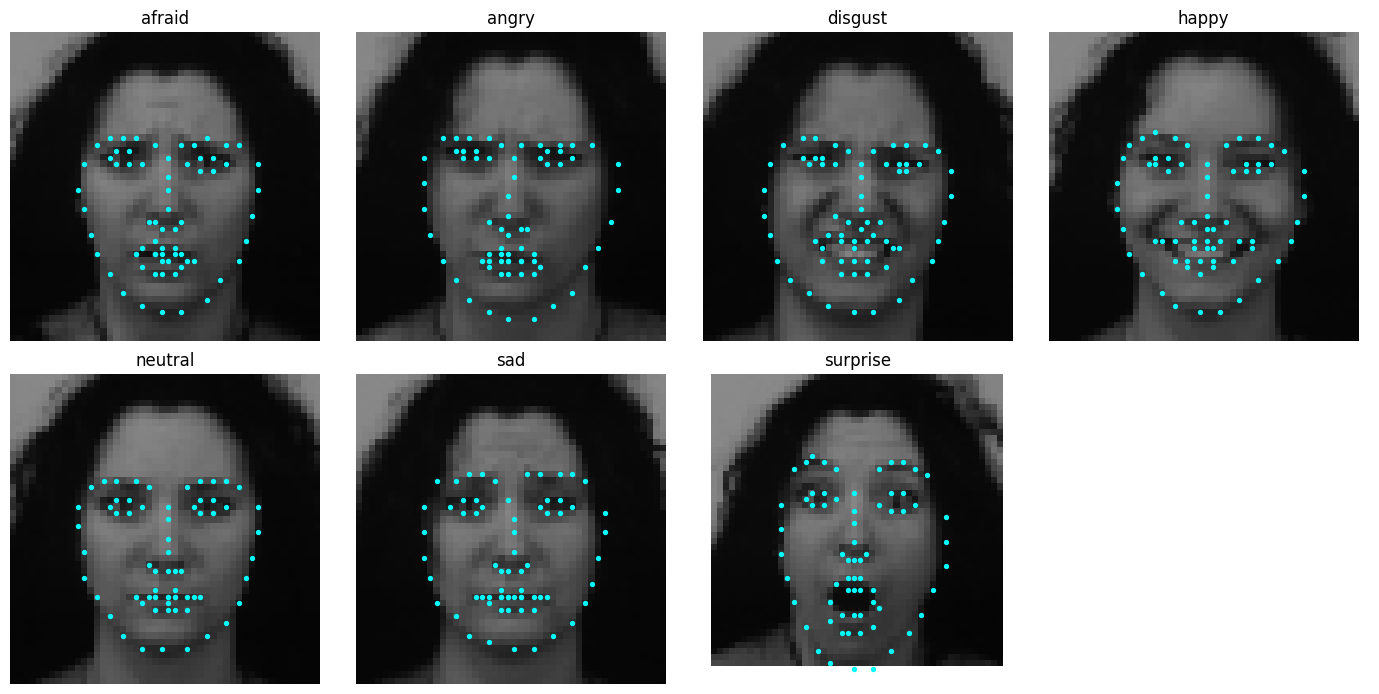

In [5]:
emotions = np.unique(y_train)
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax, emotion in zip(axes.ravel(), emotions):
    idx = np.flatnonzero(y_train == emotion)[0]
    points = landmarks_train[idx]

    ax.imshow(X_train[idx], cmap="gray", vmin=0, vmax=1)
    ax.scatter(points[:, 0], points[:, 1], s=8, color="cyan")
    ax.set_title(emotion)
    ax.axis("off")

for ax in axes.ravel()[len(emotions):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
FEATURE_NAMES = [
    "mouth_opening",
    "mouth_width",
    "eye_opening",
    "eyebrow_height",
    "brow_separation",
    "smile_curvature",
    "mouth_aspect_ratio",
    "inner_brow_elevation"
]


def geometric_features(points):
    def distance(a, b):
        return np.linalg.norm(a - b)

    # Eye centres
    eye_left = points[36:42].mean(axis=0)
    eye_right = points[42:48].mean(axis=0)

    # Rotate coordinates so the eye centres lie horizontally.
    # This reduces the effect of head tilt.
    eye_vector = eye_right - eye_left
    scale = np.linalg.norm(eye_vector)

    if scale < 1e-6:
        raise ValueError("Eye centres are too close: inspect the landmarks.")

    horizontal = eye_vector / scale
    vertical = np.array([-horizontal[1], horizontal[0]])

    centred = points - (eye_left + eye_right) / 2
    p = np.column_stack([
        centred @ horizontal,
        centred @ vertical
    ])

    # Average of three inner-lip distances
    mouth_opening = np.mean([
        distance(p[61], p[67]),
        distance(p[62], p[66]),
        distance(p[63], p[65]),
    ]) / scale

    mouth_width = distance(p[48], p[54]) / scale

    if mouth_width < 1e-6:
        raise ValueError("Invalid mouth width: inspect the landmarks.")

    mouth_aspect_ratio = mouth_opening / mouth_width

    # Average of two opening measurements per eye
    eye_opening = np.mean([
        distance(p[37], p[41]),
        distance(p[38], p[40]),
        distance(p[43], p[47]),
        distance(p[44], p[46]),
    ]) / scale

    # Image y coordinates increase downwards:
    # eye height minus eyebrow height is normally positive.
    eyebrow_height = np.mean([
        p[36:42, 1].mean() - p[17:22, 1].mean(),
        p[42:48, 1].mean() - p[22:27, 1].mean(),
    ]) / scale

    brow_separation = distance(p[21], p[22]) / scale

    # Positive when mouth corners sit above the lip centre
    lip_centre_y = (p[51, 1] + p[57, 1]) / 2
    corners_y = (p[48, 1] + p[54, 1]) / 2
    smile_curvature = (lip_centre_y - corners_y) / scale

    # 17 and 26: outer eyebrow ends
    # 21 and 22: inner eyebrow ends

    inner_brow_elevation = np.mean([
        p[17, 1] - p[21, 1],
        p[26, 1] - p[22, 1],
    ]) / scale

    return np.array([
        mouth_opening,
        mouth_width,
        eye_opening,
        eyebrow_height,
        brow_separation,
        smile_curvature,
        mouth_aspect_ratio,
        inner_brow_elevation
    ])

In [7]:
geometry_train = np.stack([
    geometric_features(points)
    for points in landmarks_train
])

features_train_df = pd.DataFrame(
    geometry_train,
    columns=FEATURE_NAMES
)

features_train_df["emotion"] = y_train

assert np.isfinite(geometry_train).all()

print("Training feature shape:", geometry_train.shape)
features_train_df.head(10)

Training feature shape: (784, 8)


,mouth_opening,mouth_width,eye_opening,eyebrow_height,brow_separation,smile_curvature,mouth_aspect_ratio,inner_brow_elevation,emotion
0,0.062575,0.704131,0.155517,0.232583,0.311033,0.041317,0.088868,9.269513e-09,afraid
1,0.025622,0.696053,0.115299,0.166125,0.230599,0.001477,0.036810,-4.135894e-02,angry
2,0.202127,0.988281,0.083647,0.214427,0.303191,0.153687,0.204524,-3.782317e-02,disgust
3,0.155774,1.083080,0.090257,0.264156,0.433232,0.180304,0.143825,3.606082e-02,happy
4,0.025641,0.769231,0.153846,0.276923,0.461538,0.076923,0.033333,0.000000e+00,neutral
5,0.025000,0.825000,0.150000,0.345000,0.382427,0.075000,0.030303,3.750001e-02,sad
6,0.314462,0.627382,0.194543,0.453793,0.544720,0.002019,0.501229,3.683768e-02,surprise
7,0.196991,0.886460,0.073872,0.289222,0.369358,0.110505,0.222222,1.132333e-01,afraid
8,0.000000,0.768978,0.115347,0.287385,0.317058,0.036465,0.000000,3.942182e-02,angry
9,0.000000,0.661802,0.091355,0.273353,0.438503,0.074777,0.000000,-3.649850e-02,disgust


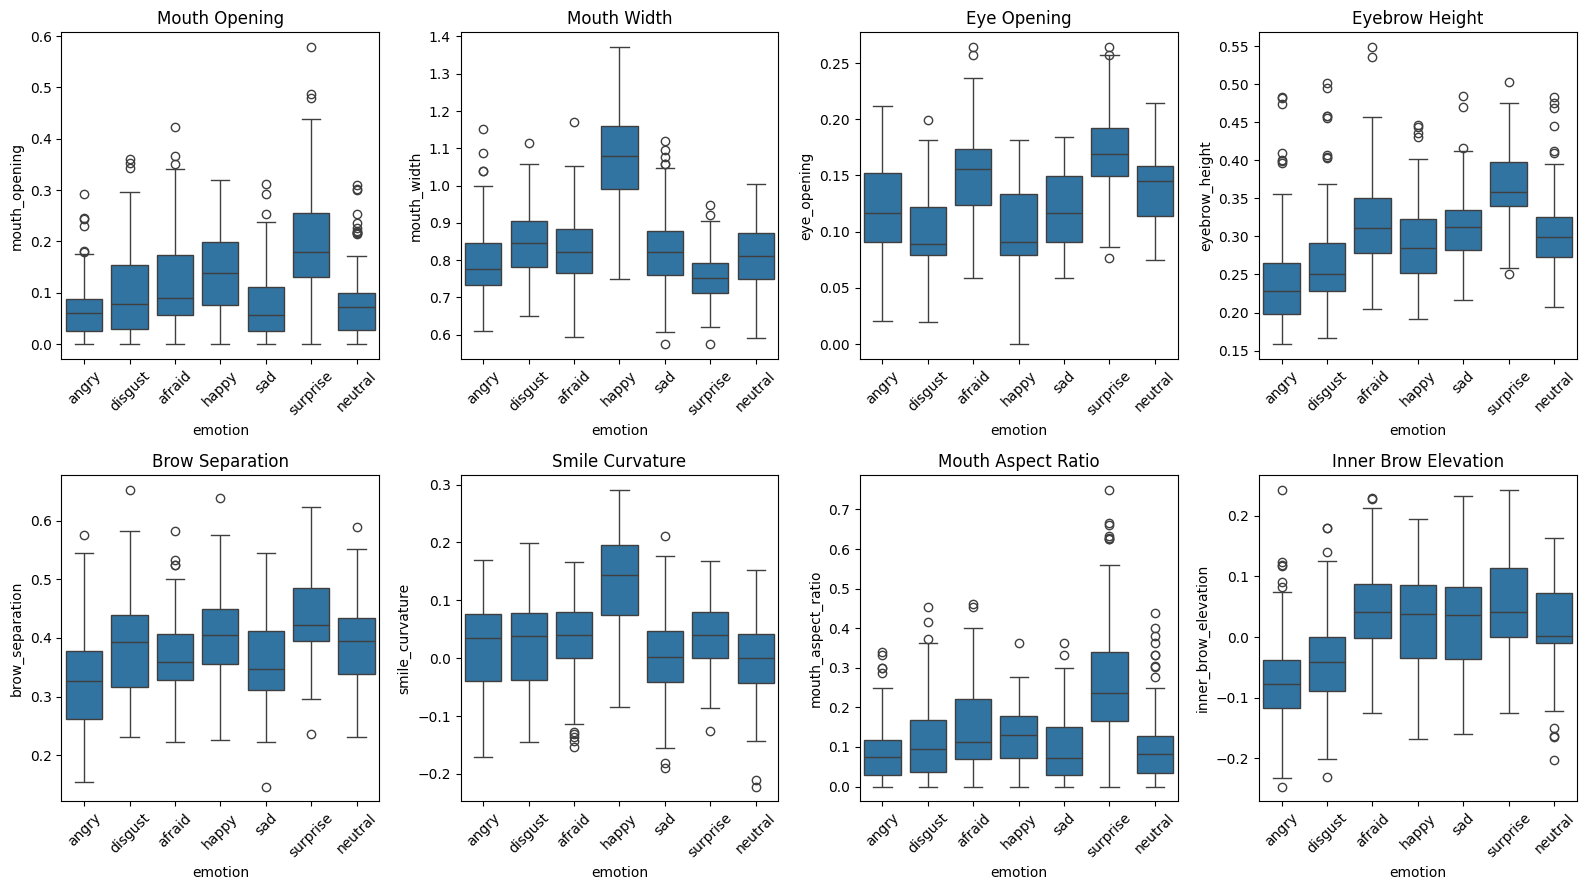

In [8]:
emotion_order = [
    "angry", "disgust", "afraid",
    "happy", "sad", "surprise", "neutral"
]

fig, axes = plt.subplots(2, 4, figsize=(16, 9))

for ax, feature in zip(axes.ravel(), FEATURE_NAMES):
    sns.boxplot(
        data=features_train_df,
        x="emotion",
        y=feature,
        order=emotion_order,
        ax=ax
    )

    ax.set_title(feature.replace("_", " ").title())
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [9]:
# Membership definitions:
# Compare this version using training/validation subjects.
fuzzy_sets = {}

for feature in FEATURE_NAMES:
    values = features_train_df[feature].to_numpy()

    minimum = values.min()
    low, middle, high = np.percentile(values, [10, 50, 90])
    maximum = values.max()

    if not low < middle < high:
        raise ValueError(
            f"{feature}: inspect the distribution "
            "and choose thresholds manually."
        )

    universe = np.unique(np.concatenate([
        np.linspace(minimum, maximum, 301),
        [low, middle, high]
    ]))

    fuzzy_sets[feature] = {
        "range": universe,

        "low": fuzz.trapmf(
            universe,
            [minimum, minimum, low, middle]
        ),

        "medium": fuzz.trimf(
            universe,
            [low, middle, high]
        ),

        "high": fuzz.trapmf(
            universe,
            [middle, high, maximum, maximum]
        ),
    }

In [10]:
EMOTIONS = [
    "angry", "disgust", "afraid", "happy",
    "sad", "surprise", "neutral"
]

x_support = np.linspace(0, 1, 201)

#Triangular-function approach 
y_support_low = fuzz.trimf(x_support, [0, 0, 0.5])
y_support_high = fuzz.trimf(x_support, [0.5, 1, 1])

In [11]:
RULES = {
    "happy": [
        [
            ("smile_curvature", "high"),
            ("mouth_width", "high"),
        ],
        [
            ("smile_curvature", "high"),
            ("eye_opening", "low"),
        ],
    ],

    "surprise": [
        [
            ("mouth_opening", "high"),
            ("eye_opening", "high"),
            ("eyebrow_height", "high"),
        ],
    ],

    "afraid": [
        [
            ("eye_opening", "high"),
            ("eyebrow_height", "medium"),
            ("mouth_opening", "medium"),
        ],
    ],

    "angry": [
        [
            ("eyebrow_height", "low"),
            ("brow_separation", "low"),
            ("smile_curvature", "low"),
        ],
        [
            ("eyebrow_height", "low"),
            ("eye_opening", "low"),
            ("mouth_opening", "low"),
        ],
    ],

    "disgust": [
        [
            ("eye_opening", "low"),
            ("mouth_opening", "medium"),
            ("smile_curvature", "medium"),
        ],
    ],

    "sad": [
        [
            ("inner_brow_elevation", "high"),
            ("mouth_opening", "low"),
            ("smile_curvature", "low"),
        ],
    ],

    "neutral": [
        [
            ("smile_curvature", "medium"),
            ("eye_opening", "medium"),
            ("eyebrow_height", "medium"),
            ("mouth_aspect_ratio", "medium")
        ],
    ],
}

for emotion, rules in RULES.items():
    for number, conditions in enumerate(rules, start=1):
        text = " AND ".join(
            f"{feature} is {term}"
            for feature, term in conditions
        )
        print(f"{emotion}, rule {number}: IF {text} THEN support is high")

happy, rule 1: IF smile_curvature is high AND mouth_width is high THEN support is high
happy, rule 2: IF smile_curvature is high AND eye_opening is low THEN support is high
surprise, rule 1: IF mouth_opening is high AND eye_opening is high AND eyebrow_height is high THEN support is high
afraid, rule 1: IF eye_opening is high AND eyebrow_height is medium AND mouth_opening is medium THEN support is high
angry, rule 1: IF eyebrow_height is low AND brow_separation is low AND smile_curvature is low THEN support is high
angry, rule 2: IF eyebrow_height is low AND eye_opening is low AND mouth_opening is low THEN support is high
disgust, rule 1: IF eye_opening is low AND mouth_opening is medium AND smile_curvature is medium THEN support is high
sad, rule 1: IF inner_brow_elevation is high AND mouth_opening is low AND smile_curvature is low THEN support is high
neutral, rule 1: IF smile_curvature is medium AND eye_opening is medium AND eyebrow_height is medium AND mouth_aspect_ratio is medium T

In [12]:
def fuzzify_features(feature_values):
    feature_values = np.asarray(feature_values, dtype=float)

    if feature_values.shape != (len(FEATURE_NAMES),):
        raise ValueError("Expected one vector containing six features.")

    if not np.isfinite(feature_values).all():
        raise ValueError("Feature values must be finite.")

    memberships = {}

    for feature, value in zip(FEATURE_NAMES, feature_values):
        sets = fuzzy_sets[feature]
        universe = sets["range"]

        # Test measurements can exceed the training range.
        # Clip to the nearest boundary instead of giving all terms zero.
        value = np.clip(value, universe[0], universe[-1])

        memberships[feature] = {
            term: float(fuzz.interp_membership(
                universe,
                sets[term],
                value
            ))
            for term in ["low", "medium", "high"]
        }

    return memberships

In [13]:
print(FEATURE_NAMES)

['mouth_opening', 'mouth_width', 'eye_opening', 'eyebrow_height', 'brow_separation', 'smile_curvature', 'mouth_aspect_ratio', 'inner_brow_elevation']


In [14]:
def predict_one_fuzzy(feature_values):
    memberships = fuzzify_features(feature_values)

    scores = {}
    strengths = {}
    rule_details = {}
    aggregated_outputs = {}

    for emotion in EMOTIONS:
        emotion_rule_strengths = []

        for conditions in RULES[emotion]:
            condition_memberships = [
                memberships[feature][term]
                for feature, term in conditions
            ]

            # AND: take the minimum membership
            strength = float(
                np.fmin.reduce(condition_memberships)
            )
            emotion_rule_strengths.append(strength)

        # OR across rules supporting the same emotion
        high_strength = float(
            np.fmax.reduce(emotion_rule_strengths)
        )

        # Explicit complementary rule:
        # IF NOT(any supporting condition), support is low.
        low_strength = 1.0 - high_strength

        # Mamdani implication: clip output membership functions
        activated_high = np.fmin(
            high_strength, y_support_high
        )
        activated_low = np.fmin(
            low_strength, y_support_low
        )

        # Aggregate output sets using maximum
        aggregated = np.fmax(
            activated_low, activated_high
        )

        # Defuzzify this emotion's output separately
        score = fuzz.defuzz(
            x_support, aggregated, "centroid"
        )

        scores[emotion] = float(score)
        strengths[emotion] = high_strength
        rule_details[emotion] = emotion_rule_strengths
        aggregated_outputs[emotion] = aggregated

    # Explicit fallback when none of the supporting rules fires
    if max(strengths.values()) <= 1e-12:
        prediction = "neutral"
        status = "no rule fired; neutral fallback"

    else:
        best_score = max(scores.values())
        winners = [
            emotion for emotion in EMOTIONS
            if np.isclose(
                scores[emotion], best_score,
                rtol=0, atol=1e-10
            )
        ]

        # Fixed tie policy, independent of the true label
        prediction = (
            "neutral" if "neutral" in winners else winners[0]
        )
        status = "tie" if len(winners) > 1 else "rule decision"

    return {
        "prediction": prediction,
        "status": status,
        "scores": scores,
        "strengths": strengths,
        "rules": rule_details,
        "memberships": memberships,
        "aggregated": aggregated_outputs,
    }

In [15]:
idx = 0

example = predict_one_fuzzy(geometry_train[idx])

print("Actual emotion:", y_train[idx])
print("Predicted emotion:", example["prediction"])
print("Decision:", example["status"])

for emotion in EMOTIONS:
    print(
        f"{emotion:10s} "
        f"rule strength={example['strengths'][emotion]:.3f}, "
        f"output score={example['scores'][emotion]:.3f}"
    )

Actual emotion: afraid
Predicted emotion: neutral
Decision: tie
angry      rule strength=0.000, output score=0.167
disgust    rule strength=0.000, output score=0.167
afraid     rule strength=0.195, output score=0.333
happy      rule strength=0.000, output score=0.167
sad        rule strength=0.000, output score=0.167
surprise   rule strength=0.000, output score=0.167
neutral    rule strength=0.195, output score=0.333


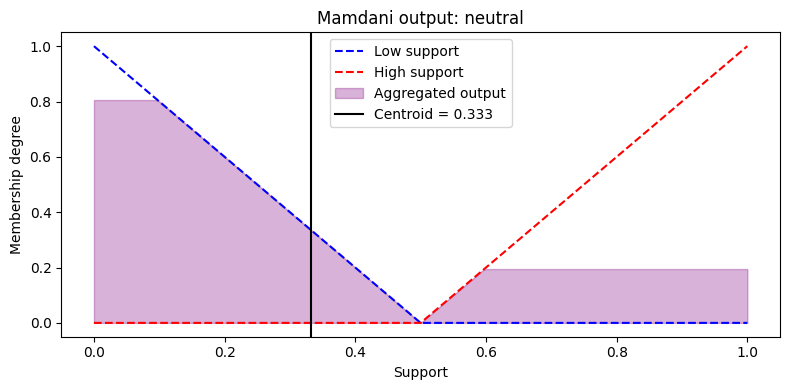

In [16]:
emotion = example["prediction"]
aggregated = example["aggregated"][emotion]
score = example["scores"][emotion]

plt.figure(figsize=(8, 4))

plt.plot(
    x_support, y_support_low,
    "b--", label="Low support"
)
plt.plot(
    x_support, y_support_high,
    "r--", label="High support"
)

plt.fill_between(
    x_support, 0, aggregated,
    color="purple", alpha=0.3,
    label="Aggregated output"
)

plt.axvline(
    score, color="black",
    label=f"Centroid = {score:.3f}"
)

plt.title(f"Mamdani output: {emotion}")
plt.xlabel("Support")
plt.ylabel("Membership degree")
plt.legend()
plt.tight_layout()
plt.show()

Fuzzy classifier — training diagnostics
Accuracy: 0.393
Balanced accuracy: 0.393
Macro F1: 0.386
              precision    recall  f1-score   support

       angry       0.37      0.44      0.40       112
     disgust       0.30      0.30      0.30       112
      afraid       0.29      0.26      0.27       112
       happy       0.48      0.70      0.57       112
         sad       0.45      0.21      0.28       112
    surprise       0.67      0.54      0.60       112
     neutral       0.26      0.31      0.28       112

    accuracy                           0.39       784
   macro avg       0.40      0.39      0.39       784
weighted avg       0.40      0.39      0.39       784

Decision types:
rule decision                      716
no rule fired; neutral fallback     41
tie                                 27
dtype: int64


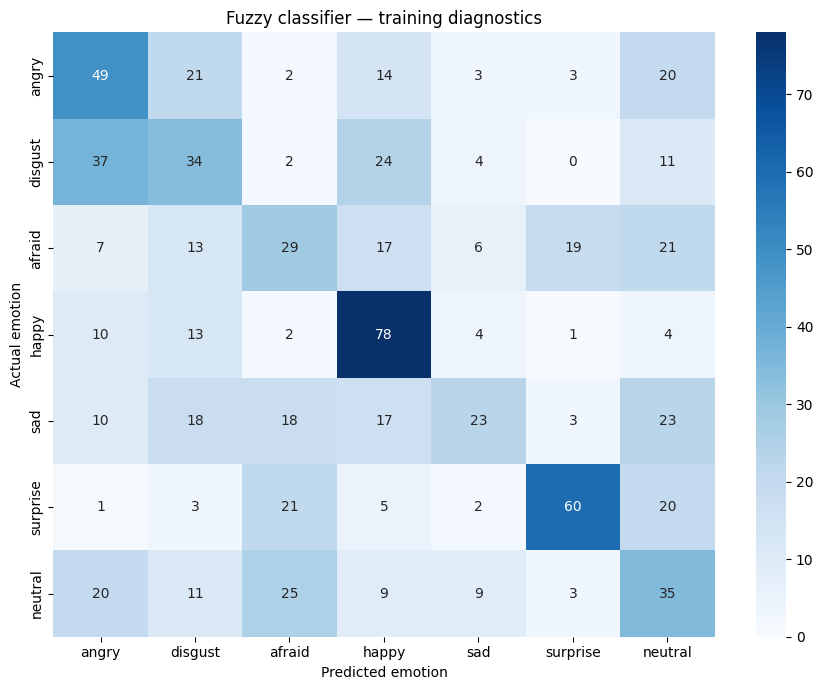

In [17]:
def predict_fuzzy_batch(feature_matrix):
    details = [
        predict_one_fuzzy(row)
        for row in feature_matrix
    ]

    predictions = np.array([
        result["prediction"] for result in details
    ])

    return predictions, details


from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)


def report_results(y_true, predictions, details, title):
    print(title)
    print(f"Accuracy: {accuracy_score(y_true, predictions):.3f}")
    print(
        "Balanced accuracy:",
        f"{balanced_accuracy_score(y_true, predictions):.3f}"
    )
    print(
        "Macro F1:",
        f"{f1_score(y_true, predictions, labels=EMOTIONS, average='macro', zero_division=0):.3f}"
    )

    print(classification_report(
        y_true,
        predictions,
        labels=EMOTIONS,
        zero_division=0
    ))

    statuses = pd.Series([
        result["status"] for result in details
    ])
    print("Decision types:")
    print(statuses.value_counts())

    matrix = confusion_matrix(
        y_true, predictions, labels=EMOTIONS
    )

    plt.figure(figsize=(9, 7))
    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=EMOTIONS,
        yticklabels=EMOTIONS
    )
    plt.xlabel("Predicted emotion")
    plt.ylabel("Actual emotion")
    plt.title(title)
    plt.tight_layout()
    plt.show()


train_predictions, train_details = predict_fuzzy_batch(
    geometry_train
)

report_results(
    y_train,
    train_predictions,
    train_details,
    "Fuzzy classifier — training diagnostics"
)

In [18]:
rows = []

for emotion in EMOTIONS:
    emotion_images = geometry_train[y_train == emotion]

    for rule_number, conditions in enumerate(
        RULES[emotion], start=1
    ):
        for feature, term in conditions:
            degrees = []

            for values in emotion_images:
                memberships = fuzzify_features(values)
                degrees.append(memberships[feature][term])

            degrees = np.asarray(degrees)

            rows.append({
                "emotion": emotion,
                "rule": rule_number,
                "condition": f"{feature} is {term}",
                "average membership": degrees.mean(),
                "fraction zero": (degrees == 0).mean(),
            })

condition_report = pd.DataFrame(rows)

display(condition_report.round(3))

,emotion,rule,condition,average membership,fraction zero
0,angry,1,eyebrow_height is low,0.684,0.116
1,angry,1,brow_separation is low,0.517,0.232
2,angry,1,smile_curvature is low,0.302,0.420
3,angry,2,eyebrow_height is low,0.684,0.116
4,angry,2,eye_opening is low,0.378,0.429
5,angry,2,mouth_opening is low,0.382,0.304
6,disgust,1,eye_opening is low,0.623,0.188
7,disgust,1,mouth_opening is medium,0.496,0.241
8,disgust,1,smile_curvature is medium,0.463,0.205
9,afraid,1,eye_opening is high,0.497,0.268


In [19]:
# One column per emotion's supporting rule strength
strengths_df = pd.DataFrame([
    result["strengths"]
    for result in train_details
])

strengths_df["actual_emotion"] = y_train

print("Average rule support for each actual emotion:")

display(
    strengths_df.groupby("actual_emotion")[EMOTIONS]
    .mean()
    .round(3)
)

Average rule support for each actual emotion:


,angry,disgust,afraid,happy,sad,surprise,neutral
actual_emotion,,,,,,,
afraid,0.052,0.077,0.189,0.095,0.044,0.090,0.110
angry,0.283,0.164,0.044,0.105,0.019,0.007,0.070
disgust,0.218,0.211,0.021,0.192,0.031,0.000,0.058
happy,0.089,0.108,0.044,0.678,0.016,0.016,0.048
neutral,0.084,0.082,0.174,0.034,0.031,0.014,0.164
sad,0.059,0.111,0.101,0.109,0.119,0.024,0.125
surprise,0.007,0.012,0.122,0.025,0.007,0.344,0.079


In [20]:
rows = []

for emotion in EMOTIONS:
    own_strengths = strengths_df.loc[
        strengths_df["actual_emotion"] == emotion,
        emotion
    ]

    rows.append({
        "emotion": emotion,
        "fraction with rule firing": (own_strengths > 0).mean(),
        "average rule strength": own_strengths.mean()
    })

display(pd.DataFrame(rows).round(3))

,emotion,fraction with rule firing,average rule strength
0,angry,0.607,0.283
1,disgust,0.491,0.211
2,afraid,0.464,0.189
3,happy,0.839,0.678
4,sad,0.304,0.119
5,surprise,0.741,0.344
6,neutral,0.509,0.164


Fuzzy classifier — held-out KDEF subjects
Accuracy: 0.423
Balanced accuracy: 0.423
Macro F1: 0.408
              precision    recall  f1-score   support

       angry       0.50      0.25      0.33        28
     disgust       0.38      0.50      0.43        28
      afraid       0.29      0.32      0.31        28
       happy       0.56      0.71      0.62        28
         sad       0.42      0.18      0.25        28
    surprise       0.50      0.61      0.55        28
     neutral       0.34      0.39      0.37        28

    accuracy                           0.42       196
   macro avg       0.43      0.42      0.41       196
weighted avg       0.43      0.42      0.41       196

Decision types:
rule decision                      179
no rule fired; neutral fallback     14
tie                                  3
dtype: int64


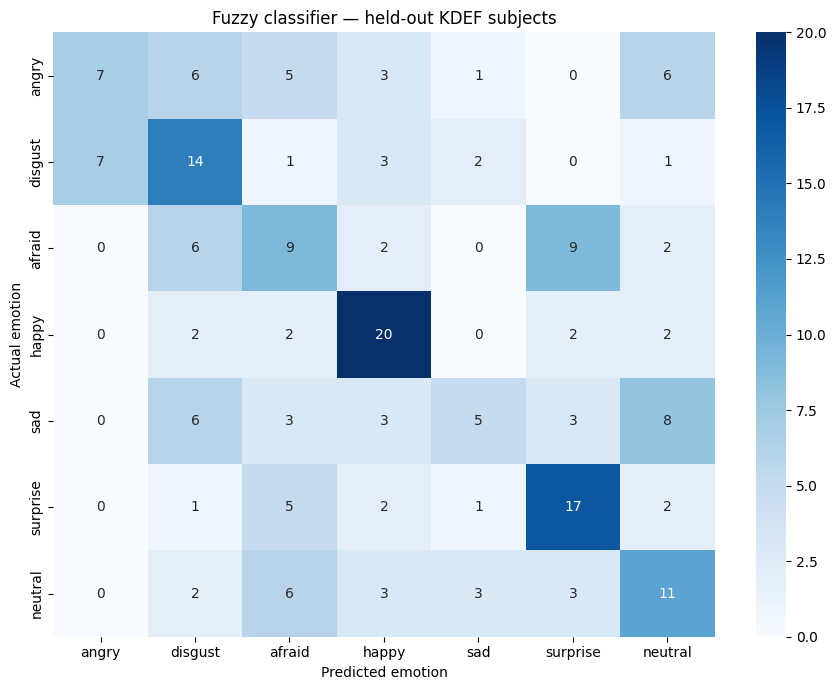

In [21]:
geometry_test = np.stack([
    geometric_features(points)
    for points in landmarks_test
])

test_predictions, test_details = predict_fuzzy_batch(
    geometry_test
)

report_results(
    y_test,
    test_predictions,
    test_details,
    "Fuzzy classifier — held-out KDEF subjects"
)

In [22]:
fuzzy_model = {
    "feature_names": FEATURE_NAMES,
    "input_sets": fuzzy_sets,
    "rules": RULES,
    "output_range": x_support,
    "output_low": y_support_low,
    "output_high": y_support_high,
    "defuzzification": "centroid",
    "no_rule_fallback": "neutral",
    "emotion_order": EMOTIONS,
}

with (BASE / "models/fuzzy_kdef_config.pkl").open("wb") as f:
    pickle.dump(fuzzy_model, f)

In [23]:
emotion_names = np.array([
    "angry",
    "disgust",
    "afraid",
    "happy",
    "sad",
    "surprise",
    "neutral"
])

assert geometry_train.shape[1] == len(FEATURE_NAMES)
assert geometry_test.shape[1] == len(FEATURE_NAMES)

assert np.isfinite(geometry_train).all()
assert np.isfinite(geometry_test).all()

assert np.isin(y_train, emotion_names).all()
assert np.isin(y_test, emotion_names).all()

# Fit scaling using training measurements only
fuzzy_scaler = StandardScaler()

X_fuzzy_train = fuzzy_scaler.fit_transform(geometry_train)
X_fuzzy_test = fuzzy_scaler.transform(geometry_test)

variable_names = np.array(FEATURE_NAMES)

print("Training:", X_fuzzy_train.shape)
print("Test:", X_fuzzy_test.shape)

Training: (784, 8)
Test: (196, 8)


In [24]:
def build_fuzzy_model(X, targets, number_of_rules=7):

    # Fuzzy clusters in training data
    clusterer = Clusterer(
        x_train=X,
        y_train=targets,
        nr_clus=number_of_rules
    )

    centers, partition_matrix, _ = clusterer.cluster(
        method="fcm"
    )

    # Input membership functions
    antecedent_estimator = AntecedentEstimator(
        x_train=X,
        partition_matrix=partition_matrix
    )

    antecedent_parameters = (
        antecedent_estimator.determineMF()
    )

    # How strongly each training image activates each rule
    strength_calculator = FireStrengthCalculator(
        antecedent_parameters=antecedent_parameters,
        nr_clus=number_of_rules,
        variable_names=variable_names
    )

    firing_strengths = (
        strength_calculator.calculate_fire_strength(data=X)
    )

    # Numerical output of each rule
    consequent_estimator = ConsequentEstimator(
        x_train=X,
        y_train=targets,
        firing_strengths=firing_strengths
    )

    consequent_parameters = consequent_estimator.suglms()

    # Executable Sugeno system
    builder = SugenoFISBuilder(
        antecedent_sets=antecedent_parameters,
        consequent_parameters=consequent_parameters,
        variable_names=variable_names,
        save_simpful_code=False
    )

    return builder.get_model(), antecedent_parameters

In [25]:
NUMBER_OF_RULES = 7

learned_fuzzy_models = {}
learned_memberships = {}

for emotion in emotion_names:
    print("\nTraining model for:", emotion)

    binary_targets = (
        y_train == emotion
    ).astype(float)

    np.random.seed(42)

    fuzzy_model, membership_parameters = build_fuzzy_model(
        X_fuzzy_train,
        binary_targets,
        number_of_rules=NUMBER_OF_RULES
    )

    learned_fuzzy_models[emotion] = fuzzy_model
    learned_memberships[emotion] = membership_parameters

print("\nAll seven models trained.")


Training model for: angry
['mouth_opening' 'mouth_width' 'eye_opening' 'eyebrow_height'
 'brow_separation' 'smile_curvature' 'mouth_aspect_ratio'
 'inner_brow_elevation']
 * Detected 7 rules / clusters
 * Detected Sugeno model type

Training model for: disgust
['mouth_opening' 'mouth_width' 'eye_opening' 'eyebrow_height'
 'brow_separation' 'smile_curvature' 'mouth_aspect_ratio'
 'inner_brow_elevation']
 * Detected 7 rules / clusters
 * Detected Sugeno model type

Training model for: afraid
['mouth_opening' 'mouth_width' 'eye_opening' 'eyebrow_height'
 'brow_separation' 'smile_curvature' 'mouth_aspect_ratio'
 'inner_brow_elevation']
 * Detected 7 rules / clusters
 * Detected Sugeno model type

Training model for: happy
['mouth_opening' 'mouth_width' 'eye_opening' 'eyebrow_height'
 'brow_separation' 'smile_curvature' 'mouth_aspect_ratio'
 'inner_brow_elevation']
 * Detected 7 rules / clusters
 * Detected Sugeno model type

Training model for: sad
['mouth_opening' 'mouth_width' 'eye_open

In [26]:
def predict_learned_fuzzy(X):
    score_columns = []

    for emotion in emotion_names:
        tester = SugenoFISTester(
            model=learned_fuzzy_models[emotion],
            test_data=X,
            variable_names=variable_names
        )

        output_values, _ = tester.predict()

        score_columns.append(
            np.asarray(output_values).reshape(-1)
        )
        
    scores = np.column_stack(score_columns)

    if not np.isfinite(scores).all():
        raise ValueError(
            "Invalid model outputs. Inspect the learned memberships."
        )

    winning_columns = np.argmax(scores, axis=1)
    predictions = emotion_names[winning_columns]

    return predictions, scores

In [27]:
learned_train_predictions, learned_train_scores = (
    predict_learned_fuzzy(X_fuzzy_train)
)

print("Training accuracy:",
      accuracy_score(y_train, learned_train_predictions))

print("Training macro F1:",
      f1_score(
          y_train,
          learned_train_predictions,
          labels=emotion_names,
          average="macro",
          zero_division=0
      ))

Training accuracy: 0.5127551020408163
Training macro F1: 0.48041905559780546


In [28]:
learned_test_predictions, learned_test_scores = (
    predict_learned_fuzzy(X_fuzzy_test)
)

learned_result = {
    "Model": "pyFUME — seven binary Sugeno models",
    "Accuracy": accuracy_score(
        y_test, learned_test_predictions
    ),
    "Balanced accuracy": balanced_accuracy_score(
        y_test, learned_test_predictions
    ),
    "Macro F1": f1_score(
        y_test,
        learned_test_predictions,
        labels=emotion_names,
        average="macro",
        zero_division=0
    )
}

display(pd.DataFrame([learned_result]).round(3))

print(classification_report(
    y_test,
    learned_test_predictions,
    labels=emotion_names,
    zero_division=0
))

,Model,Accuracy,Balanced accuracy,Macro F1
0,pyFUME — seven binary Sugeno models,0.485,0.485,0.454


              precision    recall  f1-score   support

       angry       0.41      0.50      0.45        28
     disgust       0.45      0.36      0.40        28
      afraid       0.40      0.14      0.21        28
       happy       0.64      0.89      0.75        28
         sad       0.47      0.29      0.36        28
    surprise       0.43      0.82      0.57        28
     neutral       0.52      0.39      0.45        28

    accuracy                           0.48       196
   macro avg       0.48      0.48      0.45       196
weighted avg       0.48      0.48      0.45       196



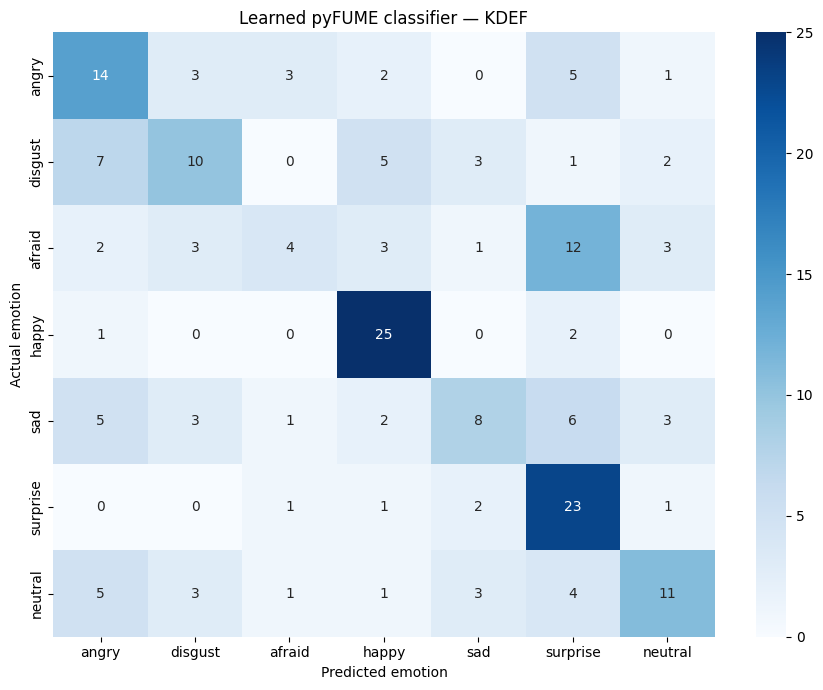

In [29]:
matrix = confusion_matrix(
    y_test,
    learned_test_predictions,
    labels=emotion_names
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

plt.xlabel("Predicted emotion")
plt.ylabel("Actual emotion")
plt.title("Learned pyFUME classifier — KDEF")
plt.tight_layout()
plt.show()

In [30]:
with (BASE / "auxFiles/kdef_subject_split.pkl").open("rb") as f:
    subject_split = pickle.load(f)

original_train_subjects = set(subject_split["train_subjects"])
original_test_subjects = set(subject_split["test_subjects"])

emotion_codes = {
    "AF": "afraid",
    "AN": "angry",
    "DI": "disgust",
    "HA": "happy",
    "NE": "neutral",
    "SA": "sad",
    "SU": "surprise",
}

recovered_subjects = []

for image_path in (BASE / "data/KDEF_and_AKDEF/KDEF").rglob("*.JPG"):
    filename = image_path.stem

    subject = filename[1:4]
    emotion_code = filename[4:6]
    pose = filename[6:]

    if subject not in original_train_subjects:
        continue

    if emotion_code not in emotion_codes or pose != "S":
        continue

    position = len(recovered_subjects)

    if position >= len(X_train):
        raise ValueError("More source images than saved training images.")

    recovered_image = preprocess_kdef_image(str(image_path))

    correct_emotion = (
        emotion_codes[emotion_code] == y_train[position]
    )

    correct_image = np.allclose(
        recovered_image,
        X_train[position],
        rtol=0,
        atol=1e-6
    )

    if not correct_emotion or not correct_image:
        raise ValueError(
            f"Image order could not be verified at {image_path.name}. "
            "Stop here: do not create the validation split."
        )

    recovered_subjects.append(subject)

subjects_train = np.asarray(recovered_subjects)

assert len(subjects_train) == len(X_train) == len(geometry_train)
assert set(subjects_train).isdisjoint(original_test_subjects)

print("Subject IDs verified for", len(subjects_train), "training images.")
print("Number of training subjects:", len(np.unique(subjects_train)))

Subject IDs verified for 784 training images.
Number of training subjects: 56


In [31]:
subject_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

anfis_train_indices, anfis_valid_indices = next(
    subject_splitter.split(
        geometry_train,
        y_train,
        groups=subjects_train
    )
)

# Reuse the existing geometric measurements.
anfis_train_features = geometry_train[anfis_train_indices]
anfis_valid_features = geometry_train[anfis_valid_indices]

anfis_y_train = y_train[anfis_train_indices]
anfis_y_valid = y_train[anfis_valid_indices]

training_people = set(subjects_train[anfis_train_indices])
validation_people = set(subjects_train[anfis_valid_indices])

assert training_people.isdisjoint(validation_people)

assert set(anfis_y_train) == set(emotion_names)
assert set(anfis_y_valid) == set(emotion_names)

print("Training images:", len(anfis_y_train))
print("Validation images:", len(anfis_y_valid))
print("Shared subjects:", training_people & validation_people)

Training images: 616
Validation images: 168
Shared subjects: set()


In [32]:
anfis_scaler = StandardScaler()

anfis_X_train = anfis_scaler.fit_transform(
    anfis_train_features
)

anfis_X_valid = anfis_scaler.transform(
    anfis_valid_features
)

assert np.isfinite(anfis_X_train).all()
assert np.isfinite(anfis_X_valid).all()

print("ANFIS training shape:", anfis_X_train.shape)
print("ANFIS validation shape:", anfis_X_valid.shape)

ANFIS training shape: (616, 8)
ANFIS validation shape: (168, 8)


In [33]:
class ANFIS:
    def __init__(self, n_clusters, X):

        self.n_clusters = n_clusters
        self.n_features = X.shape[1]

        kmeans = KMeans(
            n_clusters=n_clusters,
            random_state=42,
            n_init=10
        ).fit(X)

        self.centers = kmeans.cluster_centers_.copy()

        self.stds = np.ones(
            (n_clusters, self.n_features),
            dtype=float
        )

        self.w = None

    def _membership(self, X):
        differences = X[:, None, :] - self.centers[None, :, :]

        log_strengths = -np.sum(
            differences ** 2 / (2 * self.stds[None, :, :] ** 2),
            axis=2
        )

        log_strengths -= log_strengths.max(
            axis=1,
            keepdims=True
        )

        strengths = np.exp(log_strengths)

        return strengths / strengths.sum(
            axis=1,
            keepdims=True
        )

    def fit(
        self,
        X,
        y,
        Xv,
        yv,
        epochs=100,
        lr=0.001,
        patience=15
    ):
        best_validation_mse = np.inf
        best_parameters = None
        waiting = 0

        self.history_ = []

        for epoch in range(epochs):
            memberships = self._membership(X)

            self.w = np.linalg.lstsq(
                memberships,
                y,
                rcond=None
            )[0]

            train_predictions = memberships @ self.w
            valid_predictions = self.predict(Xv)

            train_mse = mean_squared_error(
                y, train_predictions
            )
            valid_mse = mean_squared_error(
                yv, valid_predictions
            )

            self.history_.append({
                "epoch": epoch + 1,
                "training_mse": train_mse,
                "validation_mse": valid_mse
            })

            if valid_mse < best_validation_mse:
                best_validation_mse = valid_mse
                self.best_epoch_ = epoch + 1

                best_parameters = (
                    self.centers.copy(),
                    self.stds.copy(),
                    self.w.copy()
                )

                waiting = 0
            else:
                waiting += 1

            if epoch == 0 or (epoch + 1) % 10 == 0:
                print(
                    f"Epoch {epoch + 1}: "
                    f"training MSE = {train_mse:.4f}, "
                    f"validation MSE = {valid_mse:.4f}",
                    flush=True
                )

            if waiting >= patience:
                print("Early stopping.", flush=True)
                break

            if epoch == epochs - 1:
                break

            differences = (
                X[:, None, :] - self.centers[None, :, :]
            )

            errors = train_predictions - y

            sensitivity = memberships * (
                self.w[None, :] - train_predictions[:, None]
            )

            common = (
                2 * errors[:, None] * sensitivity
            )[:, :, None]

            gradient_centers = np.mean(
                common * differences
                / self.stds[None, :, :] ** 2,
                axis=0
            )

            gradient_widths = np.mean(
                common * differences ** 2
                / self.stds[None, :, :] ** 3,
                axis=0
            )

            gradient_centers = np.clip(
                gradient_centers, -1, 1
            )
            gradient_widths = np.clip(
                gradient_widths, -0.5, 0.5
            )

            self.centers -= lr * gradient_centers

            self.stds = np.maximum(
                self.stds - lr * gradient_widths,
                0.1
            )

        self.centers, self.stds, self.w = best_parameters
        self.best_validation_mse_ = best_validation_mse

        return self

    def predict(self, X):
        if self.w is None:
            raise ValueError("Train the model before predicting.")

        memberships = self._membership(X)

        return memberships @ self.w

In [34]:
NUMBER_OF_ANFIS_RULES = 7

anfis_models = {}

for emotion in emotion_names:
    print(f"\nTraining ANFIS for: {emotion}")

    # 1 = this emotion; 0 = another emotion.
    binary_train = (anfis_y_train == emotion).astype(float)
    binary_valid = (anfis_y_valid == emotion).astype(float)

    model = ANFIS(
        n_clusters=NUMBER_OF_ANFIS_RULES,
        X=anfis_X_train
    )

    model.fit(
        anfis_X_train,
        binary_train,
        anfis_X_valid,
        binary_valid,
        epochs=100,
        lr=0.001,
        patience=15
    )

    anfis_models[emotion] = model

    print("Best epoch:", model.best_epoch_)


Training ANFIS for: angry
Epoch 1: training MSE = 0.1009, validation MSE = 0.0913
Epoch 10: training MSE = 0.1009, validation MSE = 0.0913
Epoch 20: training MSE = 0.1009, validation MSE = 0.0913
Epoch 30: training MSE = 0.1009, validation MSE = 0.0913
Epoch 40: training MSE = 0.1009, validation MSE = 0.0913
Epoch 50: training MSE = 0.1009, validation MSE = 0.0913
Epoch 60: training MSE = 0.1009, validation MSE = 0.0913
Epoch 70: training MSE = 0.1009, validation MSE = 0.0913
Epoch 80: training MSE = 0.1009, validation MSE = 0.0913
Epoch 90: training MSE = 0.1009, validation MSE = 0.0913
Epoch 100: training MSE = 0.1009, validation MSE = 0.0913
Best epoch: 100

Training ANFIS for: disgust
Epoch 1: training MSE = 0.1070, validation MSE = 0.1054
Epoch 10: training MSE = 0.1070, validation MSE = 0.1054
Epoch 20: training MSE = 0.1070, validation MSE = 0.1054
Epoch 30: training MSE = 0.1070, validation MSE = 0.1054
Epoch 40: training MSE = 0.1070, validation MSE = 0.1054
Epoch 50: trainin

In [35]:
def predict_anfis_emotions(X):
    score_columns = []

    for emotion in emotion_names:
        model = anfis_models[emotion]
        score_columns.append(model.predict(X))

    scores = np.column_stack(score_columns)

    if not np.isfinite(scores).all():
        raise ValueError("ANFIS produced invalid scores.")

    winning_columns = np.argmax(scores, axis=1)
    predictions = emotion_names[winning_columns]

    return predictions, scores

In [36]:
anfis_results = []

datasets = {
    "Training": (anfis_X_train, anfis_y_train),
    "Validation": (anfis_X_valid, anfis_y_valid)
}

for name, (features, labels) in datasets.items():
    predictions, _ = predict_anfis_emotions(features)

    anfis_results.append({
        "Dataset": name,
        "Accuracy": accuracy_score(labels, predictions),
        "Balanced accuracy": balanced_accuracy_score(
            labels, predictions
        ),
        "Macro F1": f1_score(
            labels,
            predictions,
            labels=emotion_names,
            average="macro",
            zero_division=0
        )
    })

display(pd.DataFrame(anfis_results).round(3))

anfis_valid_predictions, _ = predict_anfis_emotions(
    anfis_X_valid
)

print(classification_report(
    anfis_y_valid,
    anfis_valid_predictions,
    labels=emotion_names,
    zero_division=0
))

,Dataset,Accuracy,Balanced accuracy,Macro F1
0,Training,0.456,0.456,0.397
1,Validation,0.446,0.446,0.384


              precision    recall  f1-score   support

       angry       0.48      0.62      0.55        24
     disgust       0.38      0.38      0.38        24
      afraid       0.00      0.00      0.00        24
       happy       0.76      0.67      0.71        24
         sad       0.00      0.00      0.00        24
    surprise       0.59      0.79      0.68        24
     neutral       0.27      0.67      0.38        24

    accuracy                           0.45       168
   macro avg       0.35      0.45      0.38       168
weighted avg       0.35      0.45      0.38       168



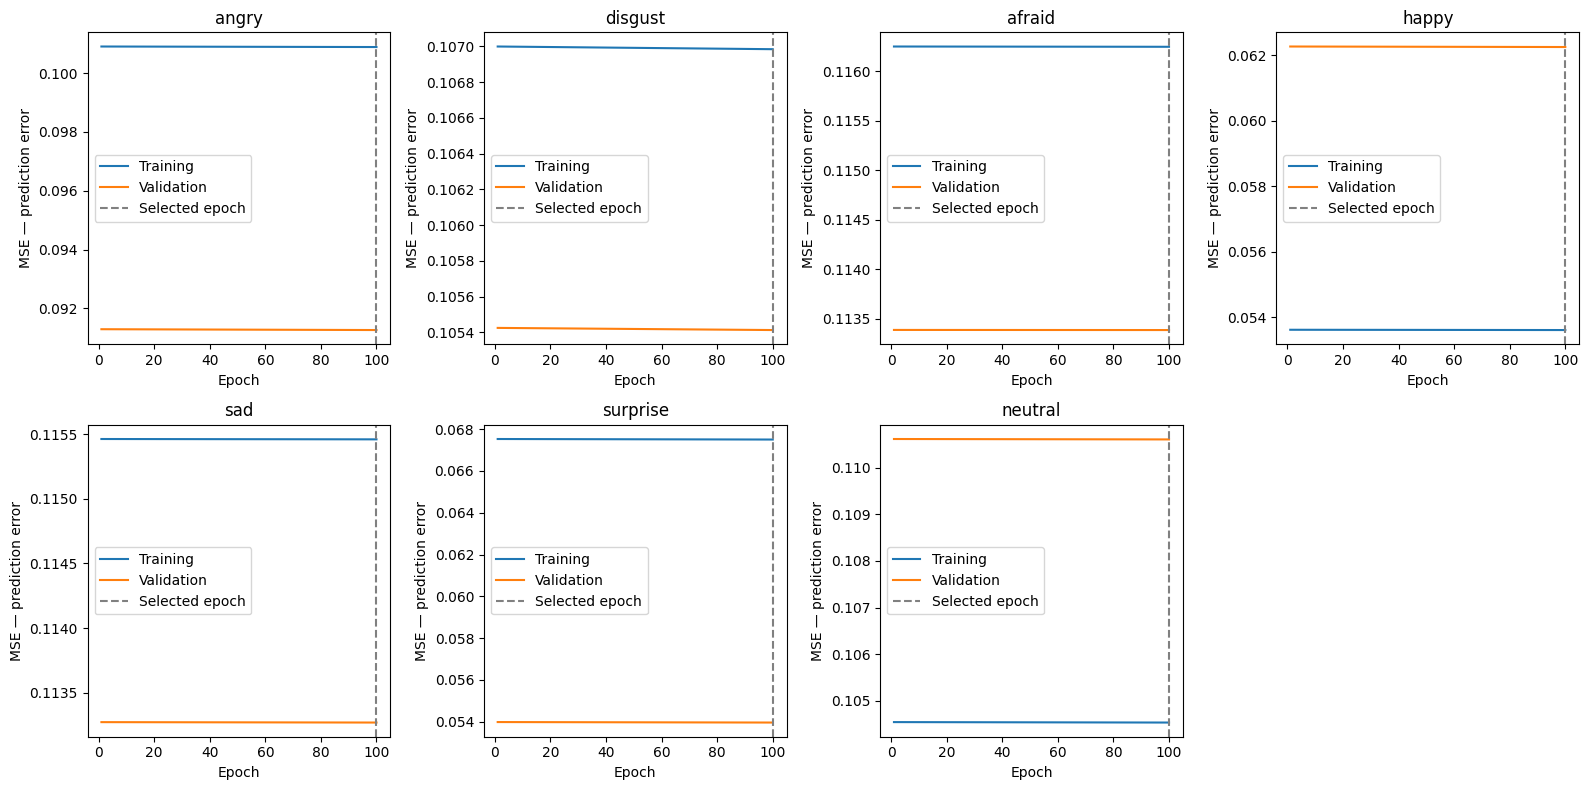

In [37]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for ax, emotion in zip(axes.ravel(), emotion_names):
    model = anfis_models[emotion]
    history = pd.DataFrame(model.history_)

    ax.plot(
        history["epoch"],
        history["training_mse"],
        label="Training"
    )

    ax.plot(
        history["epoch"],
        history["validation_mse"],
        label="Validation"
    )

    ax.axvline(
        model.best_epoch_,
        color="gray",
        linestyle="--",
        label="Selected epoch"
    )

    ax.set_title(emotion)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE — prediction error")
    ax.legend()


axes.ravel()[-1].axis("off")

plt.tight_layout()
plt.show()

In [38]:
anfis_X_test = anfis_scaler.transform(geometry_test)

assert np.isfinite(anfis_X_test).all()
assert len(anfis_X_test) == len(y_test)

print("Test feature shape:", anfis_X_test.shape)

Test feature shape: (196, 8)


In [39]:
anfis_test_predictions, anfis_test_scores = (
    predict_anfis_emotions(anfis_X_test)
)

In [40]:
anfis_test_result = {
    "Model": "ANFIS — trained on 616 images",

    "Accuracy": accuracy_score(
        y_test, anfis_test_predictions
    ),

    "Balanced accuracy": balanced_accuracy_score(
        y_test, anfis_test_predictions
    ),

    "Macro F1": f1_score(
        y_test,
        anfis_test_predictions,
        labels=emotion_names,
        average="macro",
        zero_division=0
    )
}

display(pd.DataFrame([anfis_test_result]).round(3))

print(classification_report(
    y_test,
    anfis_test_predictions,
    labels=emotion_names,
    zero_division=0
))

,Model,Accuracy,Balanced accuracy,Macro F1
0,ANFIS — trained on 616 images,0.449,0.449,0.383


              precision    recall  f1-score   support

       angry       0.42      0.46      0.44        28
     disgust       0.37      0.39      0.38        28
      afraid       0.00      0.00      0.00        28
       happy       0.80      0.71      0.75        28
         sad       1.00      0.04      0.07        28
    surprise       0.43      0.86      0.57        28
     neutral       0.36      0.68      0.47        28

    accuracy                           0.45       196
   macro avg       0.48      0.45      0.38       196
weighted avg       0.48      0.45      0.38       196



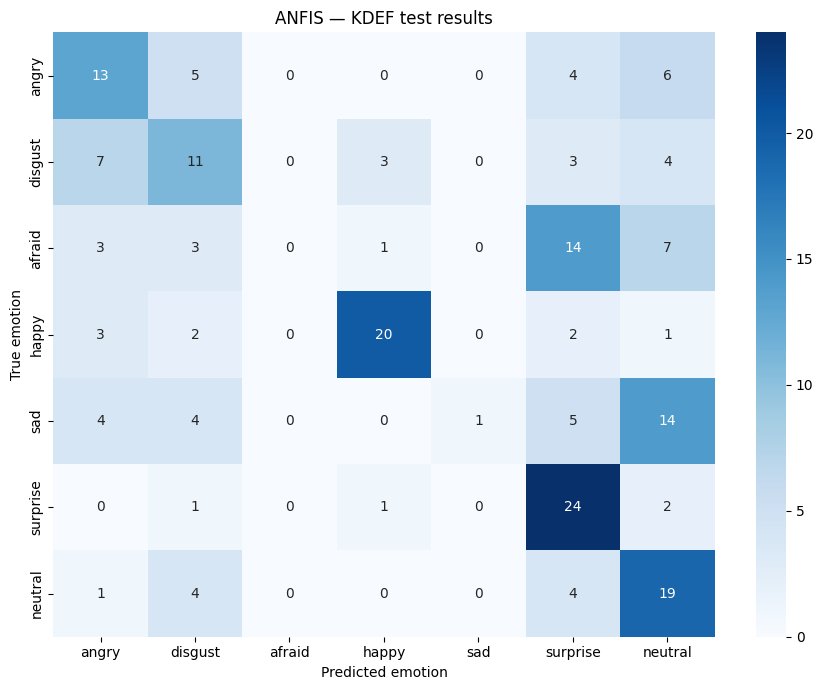

In [41]:
anfis_matrix = confusion_matrix(
    y_test,
    anfis_test_predictions,
    labels=emotion_names
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    anfis_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=emotion_names,
    yticklabels=emotion_names
)

plt.xlabel("Predicted emotion")
plt.ylabel("True emotion")
plt.title("ANFIS — KDEF test results")
plt.tight_layout()
plt.show()